In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

df = pd.read_csv('Sample - Superstore.csv', encoding='windows-1252')

df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Year_Month'] = df['Order Date'].dt.to_period('M').astype(str)

display(df.head())
print(df.info())

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year_Month
0,1,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016-11
1,2,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016-11
2,3,CA-2016-138688,2016-06-12,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016-06
3,4,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015-10
4,5,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015-10


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   object        
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

In [12]:
print("Missing Values:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

display(df[['Sales', 'Quantity', 'Discount', 'Profit']].describe())

Missing Values:
 Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
Year_Month       0
dtype: int64

Duplicate Rows: 0


,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


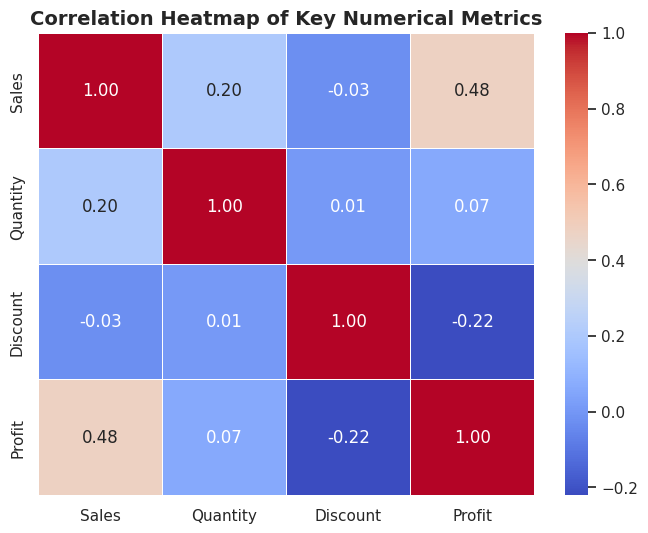

In [13]:
plt.figure(figsize=(8, 6))
numeric_cols = df[['Sales', 'Quantity', 'Discount', 'Profit']]
corr_matrix = numeric_cols.corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Key Numerical Metrics', fontsize=14, fontweight='bold')
plt.show()

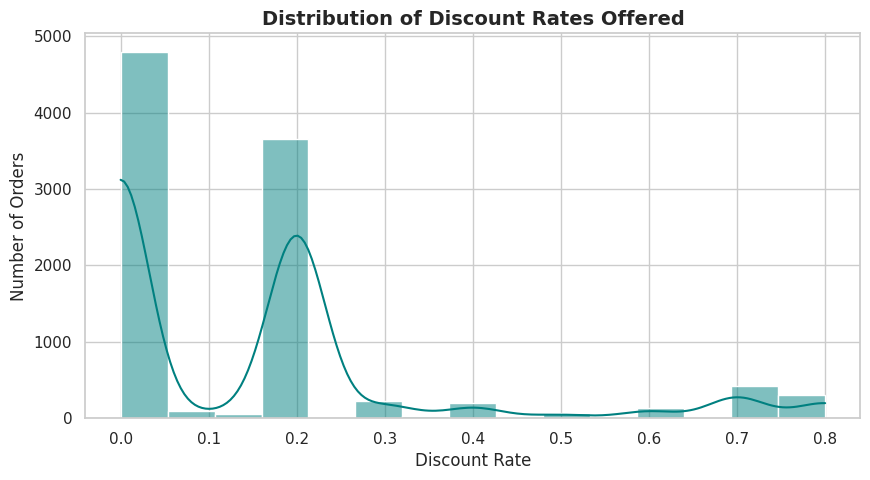

In [14]:
plt.figure(figsize=(10, 5))
sns.histplot(df['Discount'], bins=15, kde=True, color='teal')
plt.title('Distribution of Discount Rates Offered', fontsize=14, fontweight='bold')
plt.xlabel('Discount Rate')
plt.ylabel('Number of Orders')
plt.show()

/tmp/ipykernel_533/1857565010.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Category', y='Profit', data=df, palette='Set2')


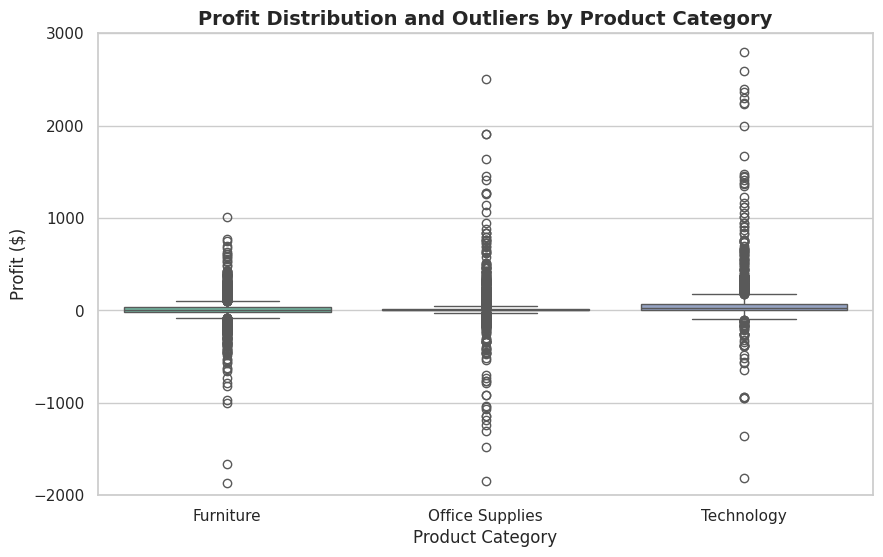

In [15]:

plt.figure(figsize=(10, 6))
sns.boxplot(x='Category', y='Profit', data=df, palette='Set2')
plt.title('Profit Distribution and Outliers by Product Category', fontsize=14, fontweight='bold')
plt.xlabel('Product Category')
plt.ylabel('Profit ($)')
plt.ylim(-2000, 3000)
plt.show()

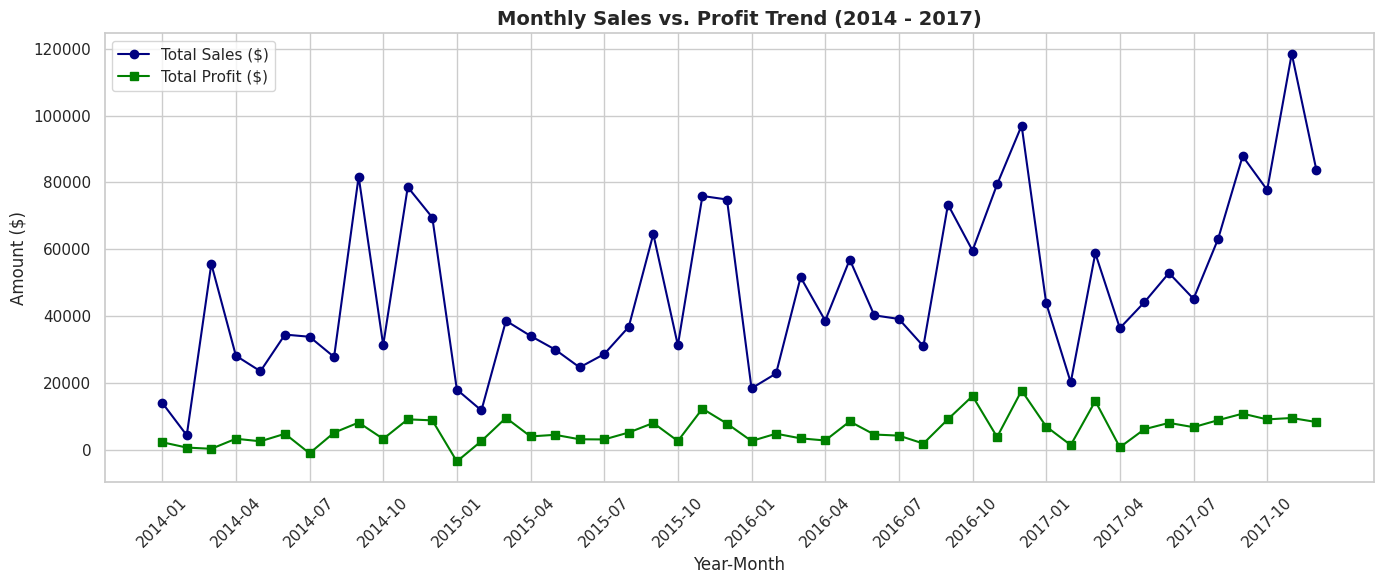

In [16]:
monthly_trends = df.groupby('Year_Month')[['Sales', 'Profit']].sum().reset_index()

plt.figure(figsize=(14, 6))
plt.plot(monthly_trends['Year_Month'], monthly_trends['Sales'], marker='o', label='Total Sales ($)', color='navy')
plt.plot(monthly_trends['Year_Month'], monthly_trends['Profit'], marker='s', label='Total Profit ($)', color='green')

plt.title('Monthly Sales vs. Profit Trend (2014 - 2017)', fontsize=14, fontweight='bold')
plt.xlabel('Year-Month')
plt.ylabel('Amount ($)')
plt.xticks(monthly_trends['Year_Month'][::3], rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

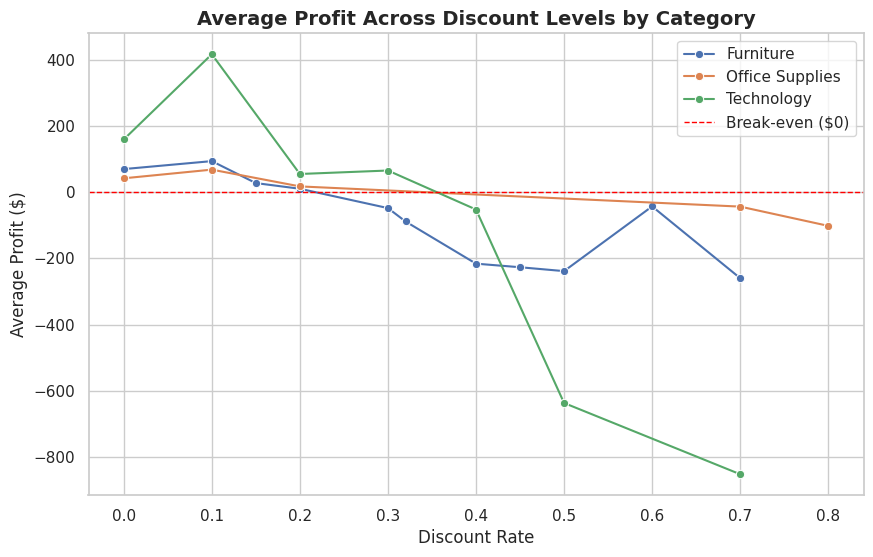

In [17]:
plt.figure(figsize=(10, 6))
sns.lineplot(x='Discount', y='Profit', hue='Category', data=df, marker='o', errorbar=None)
plt.axhline(0, color='red', linestyle='--', linewidth=1, label='Break-even ($0)')
plt.title('Average Profit Across Discount Levels by Category', fontsize=14, fontweight='bold')
plt.xlabel('Discount Rate')
plt.ylabel('Average Profit ($)')
plt.legend()
plt.show()

## Top 3 Insights

1. **Discounts Above 20% Destroy Profitability:** While 0% to 20% discounts maintain positive margins, any discount at 30% or higher pushes average order profitability into negative territory across all categories—particularly in Furniture and Technology.
2. **Strong Q4 Seasonality Drives Annual Revenue:** Sales consistently peak between September and December each year (likely driven by back-to-school and holiday shopping) and dip sharply in Q1 (January–February). Inventory and marketing budgets should be weighted toward Q4.
3. **Technology Drives High Upside, Furniture Needs Margin Review:** Technology generates the largest positive profit outliers and scales well, whereas Furniture shows frequent negative outliers and razor-thin median margins, indicating a need to audit shipping costs and discount caps on bulky furniture items.